# D5 – Mini-projet : une série temporelle

**Python numérique – devoir n° 5 – à rendre pour le dimanche 18 octobre 2026, 23 h 59** (la séance 6 est le mardi 20)

Bienvenue dans votre cinquième devoir ! Nous allons y mettre en œuvre les notions vues en séance 5 : `to_datetime`, `DatetimeIndex`, la sélection par dates, `resample`, `rolling`, `df.plot` et les figures à plusieurs sous-graphiques avec `matplotlib`. C'est aussi un mini-projet : la dernière partie est ouverte, et c'est vous qui choisissez la question à laquelle répondre.

Durée indicative : 1 h 30.

````{admonition} Consignes de rendu
:class: important

* Ce notebook reste dans le dossier `D5/` de votre dépôt `pe-homework` (celui que le zip du sujet a créé en se dézippant), avec ses figures à côté, puis il doit être **commité et poussé** (`git add`, `git commit`, `git push`) avant la deadline. Attention, c'est la **date du commit** qui fait foi, pas celle du push ; le nom du fichier, lui, n'a pas d'importance (`sujet.ipynb` convient très bien). Le dossier `data/` livré avec le sujet reste lui aussi dans `D5/` : `git add D5` embarque tout le dossier, et c'est très bien ainsi (il ne pèse que quelques kilo-octets).
* Juste avant de rendre, **pensez à ré-exécuter toutes les cellules** via *Kernel → Restart Kernel and Run All Cells* : toutes doivent s'exécuter dans l'ordre et sans erreur. En effet, un notebook qui plante à mi-chemin sera corrigé jusqu'à l'erreur…
* Le notebook lit les données dans `data/comptage-velos.csv` (chemin relatif) ; la figure `serie.png` est quant à elle écrite dans le dossier du notebook.
* Les cellules `# votre code` sont à compléter ; vous pouvez ajouter autant de cellules que vous le souhaitez. Les cellules de test (`assert`) sont là pour vous aider : si elles passent sans erreur, c'est bon signe. Ne les modifiez pas !
* Répondez aux questions "en français" dans une cellule *Markdown*, en deux ou trois phrases. Dans ce devoir, la rédaction compte autant que le code.
````

````{admonition} Ce qui est autorisé
:class: note

* La documentation de `pandas` / `matplotlib`, les notebooks du cours, vos notes.
* Les assistants IA sont tolérés, avec la règle habituelle : **vous devez être capable d'expliquer chaque ligne que vous rendez**, et je pourrai vous demander de le faire à l'oral en séance. Le devoir est individuel.
* En revanche, pas de boucle `for` sur les lignes de la série : tout se fait avec les opérations `pandas`.
````

````{admonition} Les données
:class: warning

`data/comptage-velos.csv` contient le nombre de vélos comptés chaque jour par un compteur automatique installé sur une piste cyclable parisienne, du 1er janvier 2023 au 31 décembre 2024 : une colonne `date` (texte `AAAA-MM-JJ`) et une colonne `comptage`, séparées par `;`.

Attention, **ces données sont simulées** : je les ai produites avec le script `data/generate.py`, en fixant la graine afin que tout le monde travaille sur les mêmes valeurs. Vous pouvez le lire, mais seulement *après* avoir fait le devoir ! Elles ont cependant l'allure de vraies données de comptage, défauts compris : le fichier n'est pas trié, certaines lignes sont en double, certains jours n'ont pas de mesure, et le capteur a eu au moins deux ratés. Ainsi, comme dans la vraie vie, vous allez d'abord nettoyer, puis analyser.
````

## Barème

| Exercice | Contenu | Points |
|---|---|---|
| 1 | Chargement, index temporel, diagnostic et nettoyage | 6 |
| 2 | Rééchantillonnage (`resample`) et lissage (`rolling`) | 4 |
| 3 | Profils hebdomadaire et mensuel, 2023 vs 2024 | 4 |
| 4 | Figure à deux sous-graphiques `serie.png` | 3 |
| 5 | Question ouverte : une question, une figure, trois lignes de conclusion | 3 |
| **Total** | | **20** |
| Bonus | Jour le plus creux, croissance annuelle | +2 |

*Inspiré des exercices de <https://numerique-exos.info-mines.paris>.*

In [224]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Exercice 1 – Charger, indexer, nettoyer (6 pts)

**1.a** Lisez le fichier dans une `DataFrame` `df` et affichez `df.info()`. Quel est le type de la colonne `date` ? Pourquoi n'est-ce pas satisfaisant ? Le fichier est-il trié par date ?

In [225]:
df = pd.read_csv("data/comptage-velos.csv", sep=';')
df.info(), df.tail()

<class 'pandas.DataFrame'>
RangeIndex: 734 entries, 0 to 733
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   date      734 non-null    str    
 1   comptage  726 non-null    float64
dtypes: float64(1), str(1)
memory usage: 18.8 KB


(None,
            date  comptage
 729  2024-12-30    1900.0
 730  2024-12-31    2126.0
 731  2023-12-21    1960.0
 732  2023-05-25    3101.0
 733  2024-02-27    2622.0)

La colonne date contient des chaînes de caractères, ce n'est pas satisfaisant car on ne peut pas faire les opérations voulues pour les dates. Le fichier n'est pas trié par date (cf `df.tail()`)

In [226]:
assert df.shape == (734, 2)
assert list(df.columns) == ["date", "comptage"]
print("ok")

ok


**1.b** Construisez maintenant la `Series` `brut` : les comptages indexés par la date, avec un vrai `DatetimeIndex`, triée par date et en flottants.

In [227]:
df["date"] = pd.to_datetime(df["date"], format="%Y-%m-%d")
brut = df.set_index(df["date"])["comptage"].sort_index()

In [228]:
assert isinstance(brut, pd.Series)
assert isinstance(brut.index, pd.DatetimeIndex)
assert brut.index.is_monotonic_increasing
assert len(brut) == 734
assert brut.index[0] == pd.Timestamp("2023-01-01") and brut.index[-1] == pd.Timestamp("2024-12-31")
print("ok")

ok


````{admonition} Pas encore vu en cours : duplicated()
:class: note

`serie.duplicated()` — ou `index.duplicated()` — renvoie un tableau de booléens de même longueur, avec `True` sur les valeurs *déjà rencontrées plus haut* : la première occurrence vaut `False`, les suivantes `True`. Ainsi, sur `[3, 1, 3, 3]`, on obtient `[False, False, True, True]`. Combiné à `~`, il permet donc de ne garder que la première occurrence de chaque valeur.
````

**1.c** Place au diagnostic. Répondez d'abord par du code, puis résumez vos observations dans une cellule Markdown :

* combien de dates apparaissent en double ? lesquelles ?
* combien de valeurs manquantes ? quels jours ?
* observez `brut.describe()` : le minimum et le maximum vous semblent-ils plausibles pour un compteur vélo ? Affichez les jours dont le comptage est nul, et ceux dont le comptage dépasse 3 fois la médiane.

In [229]:
brut[brut.index.duplicated()] #dates qui apparaissent en double

date
2023-05-25    3101.0
2023-12-21    1960.0
2024-02-27    2622.0
Name: comptage, dtype: float64

In [230]:
brut[brut.isna()] #valeurs manquantes

date
2023-02-23   NaN
2023-06-25   NaN
2023-12-01   NaN
2024-01-09   NaN
2024-02-08   NaN
2024-03-13   NaN
2024-11-17   NaN
2024-11-22   NaN
Name: comptage, dtype: float64

In [231]:
brut.describe() 

count      726.000000
mean      2454.612948
std       1646.281515
min          0.000000
25%       1770.250000
50%       2301.000000
75%       3090.000000
max      39660.000000
Name: comptage, dtype: float64

In [232]:
brut[brut == 0], brut[brut > 3*2301] #jours dont le comptage est nul, et dont le comptage dépasse 3 fois la médiane

(date
 2024-06-27    0.0
 Name: comptage, dtype: float64,
 date
 2024-07-04    39660.0
 Name: comptage, dtype: float64)

3 dates apparaissent en double : le 25 mai 2023, le 21 décembre 2023 et le 27 février 2024. Il manque 8 valeurs (`brut[brut.isna()]`). Le minimum est peu plausible (sauf si la piste cyclable était fermée...) et le maximum semble impossible aussi (un vélo serait passé toutes les 2 secondes en moyenne). 

In [233]:
assert brut.index.duplicated().sum() == 3
assert brut.isna().sum() == 8
assert (brut == 0).sum() == 1
assert (brut > 3 * brut.median()).sum() == 1
print("ok")

ok


````{admonition} Pas encore vu en cours : interpolate()
:class: note

`serie.interpolate()` remplace chaque `NaN` par une valeur déduite de ses voisins non manquants, par interpolation linéaire par défaut : sur `[10, NaN, NaN, 40]`, on obtient `[10, 20, 30, 40]`. C'est l'alternative à `fillna` quand les données ont un ordre naturel, comme ici le temps.
````

**1.d** Passons au nettoyage. Construisez la série propre `velos`, en trois temps :

1. supprimez les doublons d'index en ne gardant que la première occurrence (`duplicated()`) ;
2. remplacez les deux valeurs aberrantes (comptage nul ou supérieur à 3 fois la médiane) par `NaN` ;
3. remplissez tous les `NaN` (les 8 jours vides + les 2 aberrants) par interpolation linéaire.

Vérifiez enfin que `velos` a exactement une valeur par jour du 1er janvier 2023 au 31 décembre 2024 (soit 731 jours), et plus aucun `NaN`.

In [234]:
#1.
velos = brut[~brut.index.duplicated()]

#2.
velos[velos == 0] = np.nan
velos[velos > 3*velos.median()] = np.nan

#3.
velos.interpolate(inplace=True)

date
2023-01-01     304.0
2023-01-02    1658.0
2023-01-03    1450.0
2023-01-04    1902.0
2023-01-05    1715.0
               ...  
2024-12-27    1906.0
2024-12-28    1186.0
2024-12-29    1040.0
2024-12-30    1900.0
2024-12-31    2126.0
Name: comptage, Length: 731, dtype: float64

In [235]:
assert (len(velos.index.unique()) == 731 and len(velos[velos.isna()]) == 0)
print ("ok")
# on vérifie les conditions demandées

ok


In [236]:
assert len(velos) == 731
assert velos.isna().sum() == 0
assert not velos.index.duplicated().any()
assert (velos.index == pd.date_range("2023-01-01", "2024-12-31", freq="D")).all()
assert velos.min() > 100 and velos.max() < 6000
assert abs(velos.loc["2024-07-04"] - (velos.loc["2024-07-03"] + velos.loc["2024-07-05"]) / 2) < 1
print("ok")

ok


## Exercice 2 – Rééchantillonner et lisser (4 pts)

**2.a** Calculez :

* `hebdo` : la moyenne par semaine ;
* `mensuel` : la moyenne par mois (l'alias de fréquence des mois est `"ME"`, *month end*, depuis pandas 2.2 ; `"M"` si votre pandas est plus ancien) ;
* `annuel` : le **total** par année.

Combien de lignes ont `hebdo` et `mensuel` ? Pourquoi `hebdo` n'a-t-il pas exactement 731 / 7 lignes ?

In [237]:
hebdo = velos.resample('W').mean() # moyenne par semaine
len(hebdo)

106

In [238]:
mensuel = velos.resample('ME').mean() # moyenne par mois
len(mensuel)

24

In [239]:
annuel = velos.resample('YE').sum() # total par année
731/7

104.42857142857143

`hebdo` possède 106 lignes, et `mensuel` 24. `hebdo` n'a pas exactement 731/7 lignes car le début et la fin des semaines ne coïncident pas parfaitement avec le début et la fin des années, et il faut un nombre entier de semaines.

In [240]:
assert len(hebdo) == 106 and len(mensuel) == 24 and len(annuel) == 2
assert abs(mensuel.sum() * 30.4 - velos.sum()) / velos.sum() < 0.05
assert annuel.iloc[1] > annuel.iloc[0]
print("ok")

ok


**2.b** Calculez `lisse`, la moyenne glissante **centrée** sur 7 jours. Combien de `NaN` contient-elle, et où ? Pourquoi 7 jours est-il un bon choix de fenêtre pour cette série ? Enfin, tracez `velos` (trait fin, transparent) et `lisse` sur le même graphique, avec la méthode `.plot()` des `Series`.

In [241]:
lisse = velos.rolling(7, center=True).mean()
lisse.isna().sum(), lisse.head(), lisse.tail()

(np.int64(6),
 date
 2023-01-01            NaN
 2023-01-02            NaN
 2023-01-03            NaN
 2023-01-04    1357.285714
 2023-01-05    1433.714286
 Name: comptage, dtype: float64,
 date
 2024-12-27    1576.285714
 2024-12-28    1594.857143
 2024-12-29            NaN
 2024-12-30            NaN
 2024-12-31            NaN
 Name: comptage, dtype: float64)

`lisse` contient 6 `NaN`, situés aux 3 premières positions et aux 3 dernières positions. Pour calculer la moyenne, pandas utilise les 7 valeurs autour donc c'est normal que les 3 premières et les 3 dernières ne fonctionnent pas (les valeurs précédentes n'existent pas). 7 jours est un bon choix de fenêtre car il permet de voir les variations à l'échelle hebdomadaire.

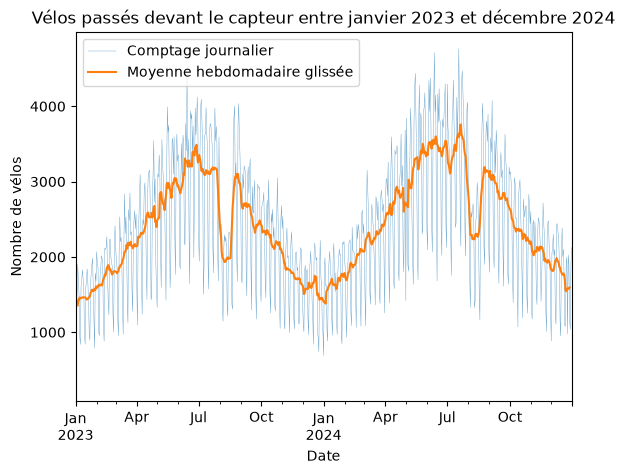

In [242]:
velos.plot(linewidth=0.3, alpha=0.7, label="Comptage journalier")
lisse.plot(label="Moyenne hebdomadaire glissée")
plt.title("Vélos passés devant le capteur entre janvier 2023 et décembre 2024")
plt.ylabel("Nombre de vélos")
plt.xlabel("Date")
plt.legend()

In [243]:
abs(lisse.loc["2023-06-15"] - velos.loc["2023-06-12":"2023-06-18"].mean())

np.float64(0.0)

In [244]:
assert len(lisse) == 731
assert lisse.isna().sum() == 6
assert abs(lisse.loc["2023-06-15"] - velos.loc["2023-06-12":"2023-06-18"].mean()) < 1e-9
print("ok")

ok


## Exercice 3 – Profils (4 pts)

**3.a** Commençons par le profil hebdomadaire : calculez `profil_semaine`, la moyenne des comptages pour chaque jour de la semaine, avec 0 = lundi … 6 = dimanche. Remplacez ensuite l'index `0..6` par les noms des jours (`"lun"`, `"mar"`, … `"dim"`). De combien (en %) le dimanche est-il plus bas que la moyenne des jours de semaine (lundi à vendredi) ?

In [245]:
velos.index.dayofweek
profil_semaine = velos.groupby(velos.index.day_of_week).mean()
profil_semaine.head(7)

date
0    2694.095238
1    2868.504762
2    2877.658654
3    2782.269231
4    2595.394231
5    1639.942308
6    1386.380952
Name: comptage, dtype: float64

In [246]:
profil_semaine.index = ["lun", "mar", "mer", "jeu", "ven", "sam", "dim"]
mean = profil_semaine[['lun', 'mar','mer','jeu','ven']].mean()
(mean-profil_semaine["dim"])/mean

np.float64(0.49833956914644145)

Le dimanche est plus bas de 49.8% que la moyenne des jours de la semaine.

In [247]:
assert profil_semaine.shape == (7,)
assert list(profil_semaine.index) == ["lun", "mar", "mer", "jeu", "ven", "sam", "dim"]
assert profil_semaine["sam"] < 0.75 * profil_semaine["lun"]
assert profil_semaine["dim"] < profil_semaine["sam"]
print("ok")

ok


````{admonition} Pas encore vu en cours : idxmax et idxmin
:class: note

`serie.idxmax()` renvoie l'**étiquette** de la plus grande valeur (ici un numéro de mois), alors que `serie.max()` renvoie la valeur elle-même ; `idxmin` fait de même pour la plus petite. Sur une série indexée par des dates, on récupère donc directement le `Timestamp` du maximum.
````

**3.b** Intéressons-nous maintenant à la saisonnalité : calculez `profil_mois`, la moyenne pour chaque mois de l'année (1 à 12), les deux années confondues. Quel est le mois le plus chargé ? Et que se passe-t-il en août ?

In [248]:
profil_mois = velos.groupby(velos.index.month).mean()
profil_mois.idxmax(), profil_mois[8], profil_mois

(np.int32(6),
 np.float64(2535.7741935483873),
 date
 1     1547.806452
 2     1845.000000
 3     2144.024194
 4     2585.300000
 5     3013.000000
 6     3313.183333
 7     3285.483871
 8     2535.774194
 9     2693.766667
 10    2309.419355
 11    1924.308333
 12    1657.911290
 Name: comptage, dtype: float64)

Le mois le plus chargé est le mois de juin. En août, il y a 2536 passages par jour en moyenne.

In [249]:
assert profil_mois.shape == (12,) and list(profil_mois.index) == list(range(1, 13))
assert profil_mois.idxmax() in (6, 7)
assert profil_mois[8] < profil_mois[7] and profil_mois[8] < profil_mois[9]
assert profil_mois.idxmin() in (1, 12)
print("ok")

ok


**3.c** Opposons enfin 2023 à 2024 : avec la sélection par chaîne de date, calculez la moyenne journalière de chaque année, puis la croissance en % de 2023 à 2024 (variable `croissance`). Posez-vous ensuite la même question mois par mois : construisez la table `par_mois` de forme `(12, 2)` (lignes = mois, colonnes = années) — `unstack` peut aider — et repérez le mois où la progression a été la plus forte.

In [250]:
profil_annee = velos.groupby(velos.index.year).mean()


In [251]:
croissance = (profil_annee[2024] - profil_annee[2023])/profil_annee[2023] * 100
croissance #croissance entre 2023 et 2024

np.float64(10.481613797717293)

In [252]:
par_mois = velos.groupby([velos.index.month, velos.index.year]).mean().unstack()
croissance_mois = (par_mois[2024] - par_mois[2023]) / par_mois[2024] * 100
croissance_mois

date
1     11.702378
2      9.141010
3      8.100851
4     13.815205
5     10.270265
6      5.292026
7     11.130067
8      6.233824
9     10.996901
10     6.468879
11    10.619767
12    12.374738
dtype: float64

Le mois d'avril a connu la progression la plus forte (13.8%)

In [253]:
assert 7 < croissance < 14
assert par_mois.shape == (12, 2)
assert list(par_mois.columns) == [2023, 2024]
assert (par_mois[2024] > par_mois[2023]).sum() >= 10
print("ok")

ok


## Exercice 4 – Figure à deux sous-graphiques (3 pts)

Construisez une figure `fig, (ax_haut, ax_bas) = plt.subplots(2, 1, figsize=(11, 8))` :

* en haut : la série journalière `velos` (trait fin, transparent) et la série lissée `lisse` (trait plus épais), avec une légende, un titre et un nom d'axe des ordonnées ;
* en bas : le profil hebdomadaire `profil_semaine` en barres, avec un titre et un nom d'axe des ordonnées.

Terminez par `fig.tight_layout()` et enregistrez dans `serie.png` (`fig.savefig`).

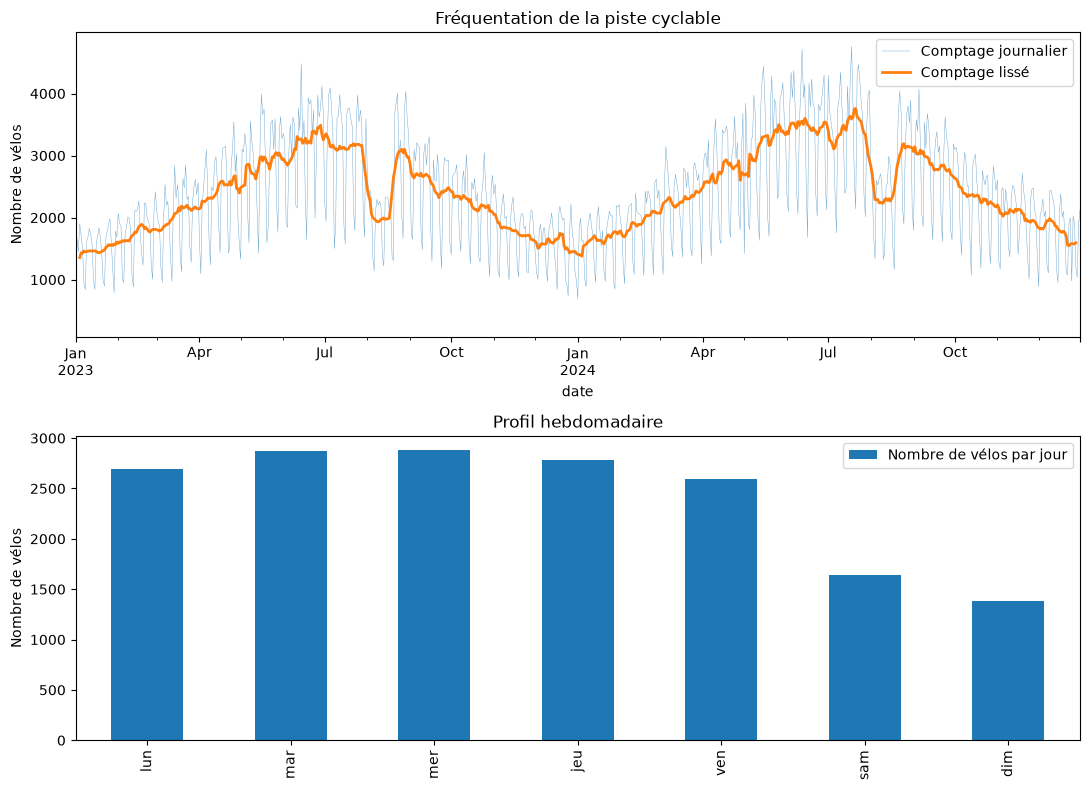

In [254]:
fig, (ax_haut, ax_bas) = plt.subplots(2, 1, figsize=(11,8))

velos.plot(ax=ax_haut, linewidth=0.3, alpha=0.7, label="Comptage journalier")
lisse.plot(ax=ax_haut, linewidth=2, alpha=1, label="Comptage lissé")
ax_haut.set_ylabel("Nombre de vélos")
ax_haut.set_title("Fréquentation de la piste cyclable")

ax_haut.legend()

profil_semaine.plot.bar(ax=ax_bas, label="Nombre de vélos par jour")
ax_bas.set_title("Profil hebdomadaire")
ax_bas.set_ylabel("Nombre de vélos")

ax_bas.legend()

fig.tight_layout()
fig.savefig("serie.png")
plt.show()

In [255]:
assert os.path.exists("serie.png")
print("ok")

ok


## Exercice 5 – Question ouverte (3 pts)

C'est ici que vous prenez la main ! Choisissez **une** question sur cette série, puis répondez-y avec une figure (au moins une courbe ou un diagramme, légendée et titrée) et trois lignes de conclusion en Markdown. Voici quelques idées, mais une question à vous est la bienvenue :

* le creux d'août a-t-il la même ampleur en 2023 et en 2024 ?
* l'écart week-end / semaine est-il le même en été et en hiver ?
* quelle semaine de l'année est la plus chargée ? la plus creuse ? est-ce la même les deux années ?
* la croissance entre 2023 et 2024 est-elle uniforme sur l'année, ou concentrée sur certains mois ?
* que se passe-t-il autour des jours fériés que vous connaissez ?

Côté barème, je compte un point pour la pertinence de la méthode, un point pour une figure lisible et correcte, et un point pour une conclusion chiffrée et honnête.

Question choisie : "l'écart week-end / semaine est-il le même en été et en hiver ?"

46.320229207725106 44.89394778591348


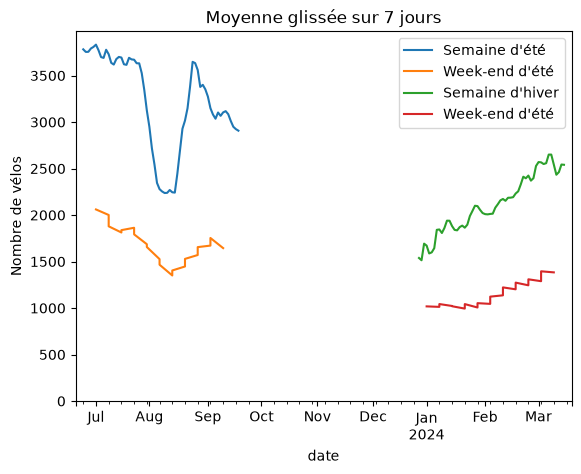

In [265]:
ete = velos["2023-06-21":"2023-09-22"]
hiver = velos["2023-12-22":"2024-03-20"]
#on garde que l'année 2023 parce que l'hiver 2024 n'est pas complet
semaine = [0, 1, 2, 3, 4]
weekend = [5, 6]
ete[ete.index.day_of_week.isin(semaine)].rolling(7, center=True).mean().plot(label="Semaine d'été")
ete[ete.index.day_of_week.isin(weekend)].rolling(7, center=True).mean().plot(label="Week-end d'été")
hiver[hiver.index.day_of_week.isin(semaine)].rolling(7, center=True).mean().plot(label="Semaine d'hiver")
hiver[hiver.index.day_of_week.isin(weekend)].rolling(7, center=True).mean().plot(label="Week-end d'été")
plt.title("Moyenne glissée sur 7 jours")
plt.ylabel("Nombre de vélos")
plt.ylim(bottom=0)
plt.legend()
rapport_ete = (ete[ete.index.day_of_week.isin(semaine)].mean()-ete[ete.index.day_of_week.isin(weekend)].mean())/ete[ete.index.day_of_week.isin(semaine)].mean()*100
rapport_hiver = (hiver[hiver.index.day_of_week.isin(semaine)].mean()-hiver[hiver.index.day_of_week.isin(weekend)].mean())/hiver[hiver.index.day_of_week.isin(semaine)].mean()*100
print(rapport_ete, rapport_hiver)

Le graphique montre que la fréquentation des pistes cyclables baisse en hiver, c'est logique car il fait plus froid donc les gens prennent moins le vélo. Pour autant, le rapport entre la fréquentation en semaine et le week-end reste à peu près constant : respectivement 46% et 45% de fréquentation le week-end par rapport à la semaine. Globalement, les gens prennent moins leur vélo l'hiver mais la distribution de fréquentation sem

## Bonus (+2)

**Bo.1** Quel est le jour le plus creux de toute la série ? Et le plus chargé ? Pour chacun, donnez le jour de la semaine (`.day_name()`) et proposez une explication.

````{admonition} Pas encore vu en cours : pct_change
:class: note

`serie.pct_change()` renvoie la variation *relative* d'une valeur à la suivante : sur `[100, 110, 99]`, elle donne `[NaN, 0.10, -0.10]`. La première case vaut `NaN` faute de valeur précédente, et le résultat est une proportion, à multiplier par 100 pour l'exprimer en pourcentage.
````

**Bo.2** Calculez la croissance annuelle en % à partir des totaux annuels `annuel`. Pourquoi ce chiffre est-il légèrement différent de `croissance` (exercice 3.c) ?

In [ ]:
# votre code

Bon courage à tous ! Pour toute question sur le sujet, vous pouvez me contacter par email : [raphael@imagine-app.fr](mailto:raphael@imagine-app.fr).

Au plaisir de vous lire,

votre responsable de cours, Raphael Prasquier
(sujet conçu par Aurélien Noce)